# SPACEc: ML-enabled cell type annotation - STELLAR

After preprocessing the single-cell data, the next step is to assign cell types. Alternatively to the SVM (see notebook 05_cell_annotation_ml) model we included a wrapper for STELLAR, that allows to use the model in a more user-friendly way. Further information about STELLAR can be found here: http://snap.stanford.edu/stellar/

In [ ]:
# import spacec first
import spacec as sp

#import standard packages
import os
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
import scanpy as sc
import seaborn as sns
import sys
import os
import anndata
import numpy as np

# silencing warnings
import warnings
warnings.filterwarnings('ignore')

sc.settings.set_figure_params(dpi=80, facecolor='white')

In [2]:
# Apply SPACEc publication style to all plots in this notebook
sp.pl.set_style(sp.pl.SPACEcStyle.publication())

In [3]:
# STELLAR is an optional dependency. Install it once, then restart the kernel:
# PyTorch Geometric + the Python 3.12 STELLAR fork matching your torch build
# sp.tl.install_stellar()
# (or: pip install 'spacec[stellar]' and pip install git+https://github.com/TKempchen/stellar-py3.12)
# Optional: pip install 'spacec[legacy]' to use STELLAR's original louvain backend
# (louvain_flavor="vtraag"); without it adata_stellar falls back to igraph with a warning.

## Data Explanation
Annotated tonsil data is used as training & test data. </br>
Tonsillitis data is used as validation data.

In [ ]:
# Specify the path to the data
data_path = "path/to/example_data/raw/"
output_dir = "path/to/output/"
os.makedirs(output_dir, exist_ok=True)

In [ ]:
# Load training data
adata = sc.read(output_dir + "adata_nn_demo_annotated.h5ad")
adata_train = adata[adata.obs['condition'] == 'tonsil']
adata_val  = adata[adata.obs['condition'] == 'tonsillitis']

## Training

In [ ]:
# Check for NaN values in the training data
np.isnan(adata_train.X).sum()

0

In [ ]:
# Run STELLAR on the training and validation data
adata_new = sp.tl.adata_stellar(adata_train, 
               adata_val, 
               celltype_col = "cell_type", 
               x_col = 'x', 
               y_col = 'y', 
               sample_rate = 0.5, 
               distance_thres = 50,
               num_seed_class = 0)

Please consider to cite the following paper when using STELLAR: Brbić, M., Cao, K., Hickey, J.W. et al. Annotation of spatially resolved single-cell data with STELLAR. Nat Methods 19, 1411–1418 (2022). https://doi.org/10.1038/s41592-022-01651-8
Preparing input data
Number of unique cell types: 15
Cell types: ['B cell' 'CD4+ T cell' 'CD8+ T cell' 'DC' 'Epithelial cell' 'GCB'
 'M1 Macrophage' 'M2 Macrophage' 'Mast cell' 'NK cell']
Cell type mapping size: 15
First 3 mappings: [('B cell', 0), ('CD4+ T cell', 1), ('CD8+ T cell', 2)]
Building dataset
Training data shape: (13254, 59), max label index: 13253
Testing data shape: (20282, 59), max label index: 20281
Max labeled edge index: 13253
Max unlabeled edge index: 20281
Setting input dimension to: 59
Running STELLAR
Model has 42496 parameters


Computing METIS partitioning...
Done!


Loss: 2.850132


Computing METIS partitioning...
Done!


Loss: 1.768492


Computing METIS partitioning...
Done!


... (131 outputs left out)

Computing METIS partitioning...
Done!
Computing METIS partitioning...
Done!


Loss: -0.116968


Computing METIS partitioning...
Done!
Computing METIS partitioning...
Done!


Loss: -0.117658
Mean prediction uncertainty: 0.0803
Prediction distribution:
Class 0: 5946 cells (29.32%)
Class 1: 2756 cells (13.59%)
Class 2: 1246 cells (6.14%)
Class 3: 1860 cells (9.17%)
Class 4: 1481 cells (7.30%)
Class 5: 2567 cells (12.66%)
Class 6: 303 cells (1.49%)
Class 7: 612 cells (3.02%)
Class 8: 159 cells (0.78%)
Class 9: 30 cells (0.15%)
Class 10: 55 cells (0.27%)
Class 11: 1332 cells (6.57%)
Class 12: 471 cells (2.32%)
Class 13: 1042 cells (5.14%)
Class 14: 422 cells (2.08%)


## Inspect the results

In [10]:
adata_new.obs

,DAPI,x,y,area,region_num,unique_region,condition,leiden_1,leiden_1_subcluster,cell_type_coarse,cell_type_coarse_subcluster,cell_type_coarse_f,cell_type_coarse_f_subcluster,cell_type_coarse_f_f,cell_type,CN_k20_n6,CN_k20_n6_annot,stellar_pred
0,105.993197,4.986395,1472.238095,147.0,1,reg002,tonsillitis,23,"23,1",Neutrophil,Neutrophil,Neutrophil,Neutrophil,Neutrophil,Neutrophil,5,Marginal Zone B-DC-Enriched,Neutrophil
1,123.677686,5.359504,1322.851240,242.0,1,reg002,tonsillitis,13,13,M2 Macrophage,M2 Macrophage,M2 Macrophage,M2 Macrophage,M2 Macrophage,M2 Macrophage,1,Marginal Zone,M2 Macrophage
2,107.203125,5.710938,1506.226562,256.0,1,reg002,tonsillitis,23,"23,1",Neutrophil,Neutrophil,Neutrophil,Neutrophil,Neutrophil,Neutrophil,5,Marginal Zone B-DC-Enriched,Neutrophil
3,49.660959,8.544521,641.938356,292.0,1,reg002,tonsillitis,21,21,recluster,"recluster,16",B cell,B cell,B cell,B cell,4,Germinal Center,B cell
4,148.702532,9.006329,1303.702532,158.0,1,reg002,tonsillitis,12,"12,1",recluster,"recluster,12",CD4+ T cell,CD4+ T cell,CD4+ T cell,CD4+ T cell,1,Marginal Zone,B cell
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
22298,109.644269,2523.201581,1333.177866,253.0,1,reg002,tonsillitis,5,"5,1",Epithelial cell,Epithelial cell,Epithelial cell,Epithelial cell,Epithelial cell,Epithelial cell,5,Marginal Zone B-DC-Enriched,Epithelial cell
22299,50.512346,2523.888889,1384.086420,162.0,1,reg002,tonsillitis,5,"5,1",Epithelial cell,Epithelial cell,Epithelial cell,Epithelial cell,Epithelial cell,Epithelial cell,5,Marginal Zone B-DC-Enriched,Epithelial cell
22300,160.015686,2522.047059,1438.568627,255.0,1,reg002,tonsillitis,0,0,B cell,B cell,B cell,B cell,B cell,B cell,1,Marginal Zone,CD4+ T cell
22301,56.734177,2523.924051,1349.759494,79.0,1,reg002,tonsillitis,9,9,Plasma cell,Plasma cell,Plasma cell,Plasma cell,Plasma cell,Plasma cell,5,Marginal Zone B-DC-Enriched,Epithelial cell


<Axes: title={'center': 'stellar_pred'}, xlabel='UMAP1', ylabel='UMAP2'>

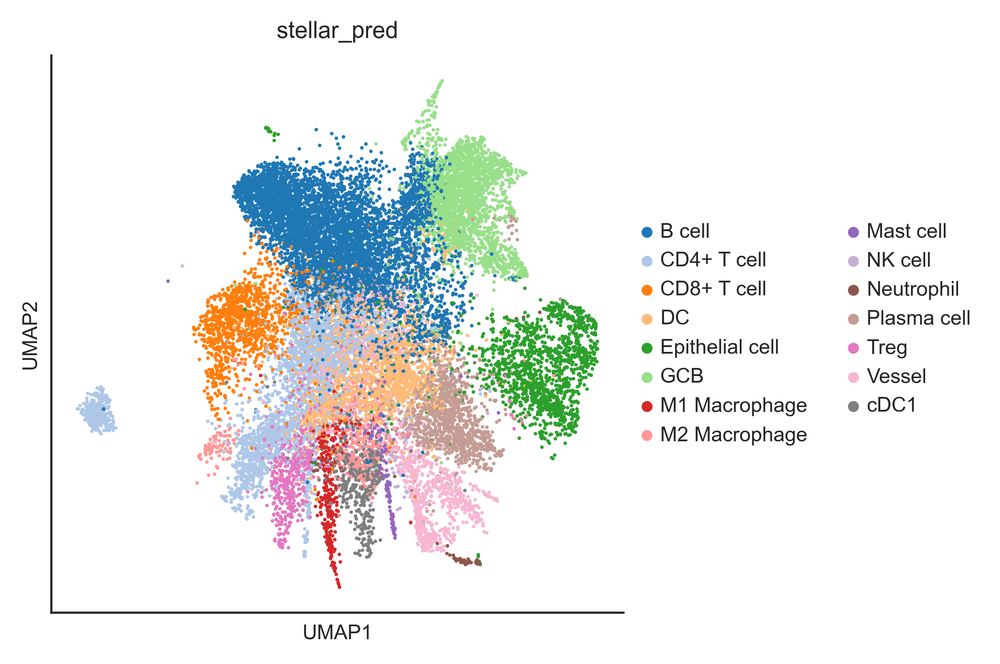

In [11]:
sp.pl.umap(adata_new, color = 'stellar_pred')

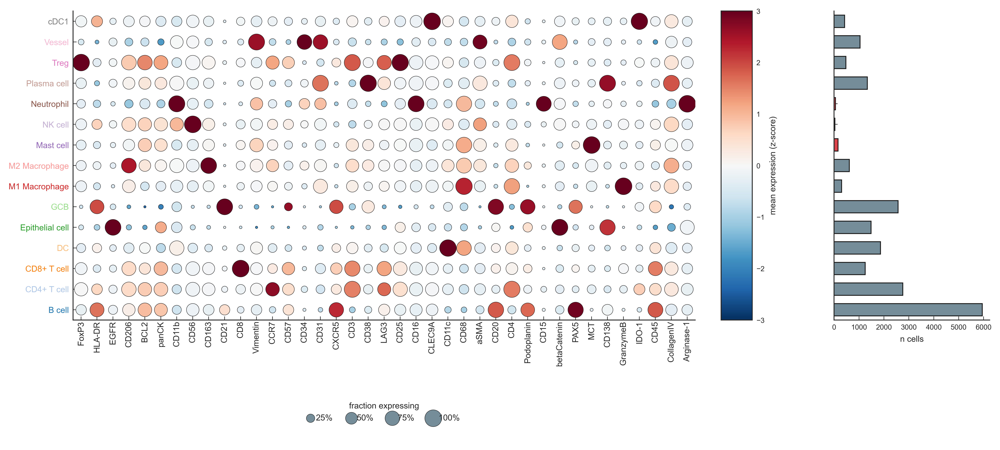

{'dots': <Axes: >,
 'size': <Axes: xlabel='n cells'>,
 'dendrogram': None,
 'spatial': None,
 'colorbar': <Axes: ylabel='mean expression (z-score)'>,
 'legend': <Axes: >}

In [22]:
marker_list = [
    'FoxP3', 'HLA-DR', 'EGFR', 'CD206', 'BCL2', 'panCK', 'CD11b', 'CD56', 'CD163', 'CD21', 'CD8', 
    'Vimentin', 'CCR7', 'CD57', 'CD34', 'CD31', 'CXCR5', 'CD3', 'CD38', 'LAG3', 'CD25', 'CD16', 'CLEC9A', 'CD11c', 
    'CD68', 'aSMA', 'CD20', 'CD4','Podoplanin', 'CD15', 'betaCatenin', 'PAX5', 
    'MCT', 'CD138', 'GranzymeB', 'IDO-1', 'CD45', 'CollagenIV', 'Arginase-1']

sp.pl.marker_dotplot(adata_new, marker_list, groupby='stellar_pred', dendrogram = False)

## Single-cell visualzation

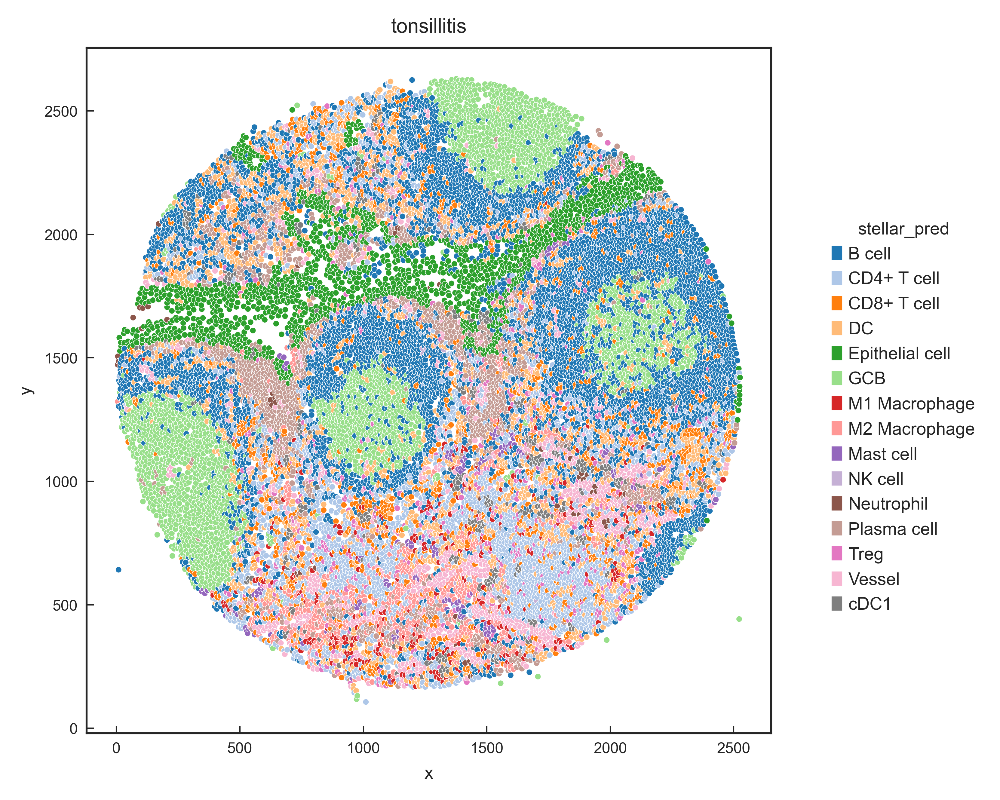

In [13]:
sp.pl.catplot(
    adata_new, color = "stellar_pred", # specify group column name here e.g. celltype_fine)
    unique_region = "condition", # specify unique_regions here
    X='x', Y='y', # specify x and y columns here
    n_columns=1, # adjust the number of columns for plotting here (how many plots do you want in one row?)
    palette=None, #default is None which means the color comes from the anndata.uns that matches the UMAP
    savefig=False, # save figure as pdf
    output_fname = "", # change it to file name you prefer when saving the figure
    output_dir=output_dir, # specify output directory here (if savefig=True)
);

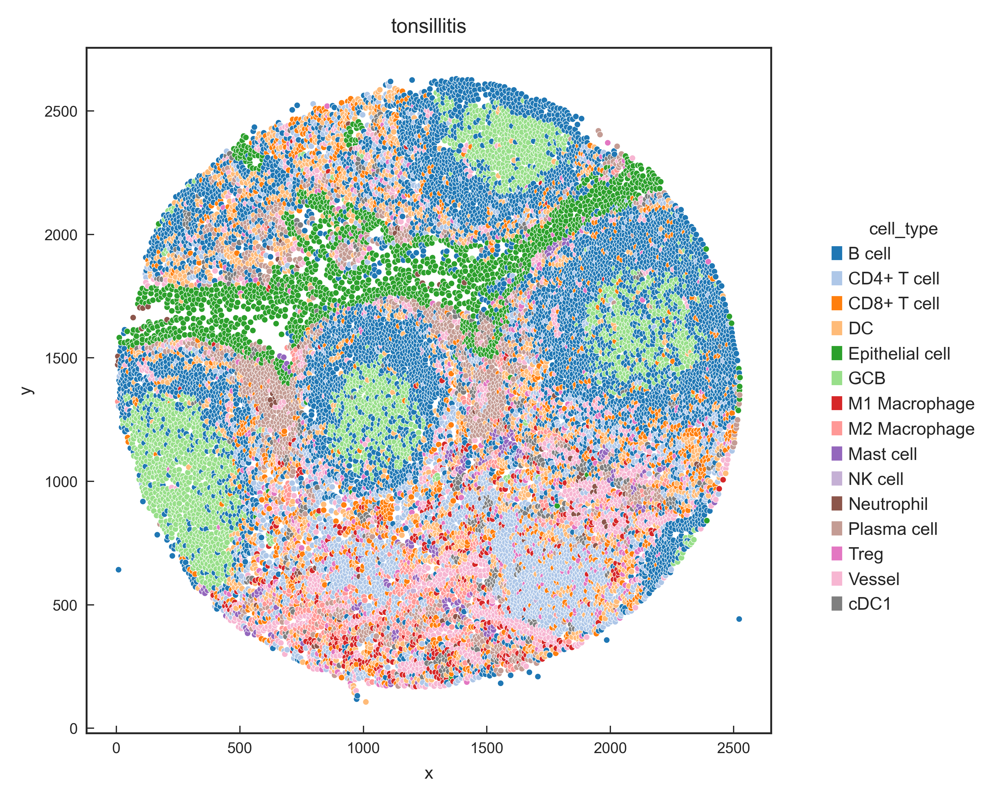

In [14]:
sp.pl.catplot(
    adata_new, color = "cell_type", # specify group column name here e.g. celltype_fine)
    unique_region = "condition", # specify unique_regions here
    X='x', Y='y', # specify x and y columns here
    n_columns=1, # adjust the number of columns for plotting here (how many plots do you want in one row?)
    palette=None, #default is None which means the color comes from the anndata.uns that matches the UMAP
    savefig=False, # save figure as pdf
    output_fname = "", # change it to file name you prefer when saving the figure
    output_dir=output_dir,); # specify output directory here (if savefig=True)

## Evaluate predictions against known cell types

<Axes: title={'center': 'Confusion Matrix'}, xlabel='Predicted label', ylabel='True label'>

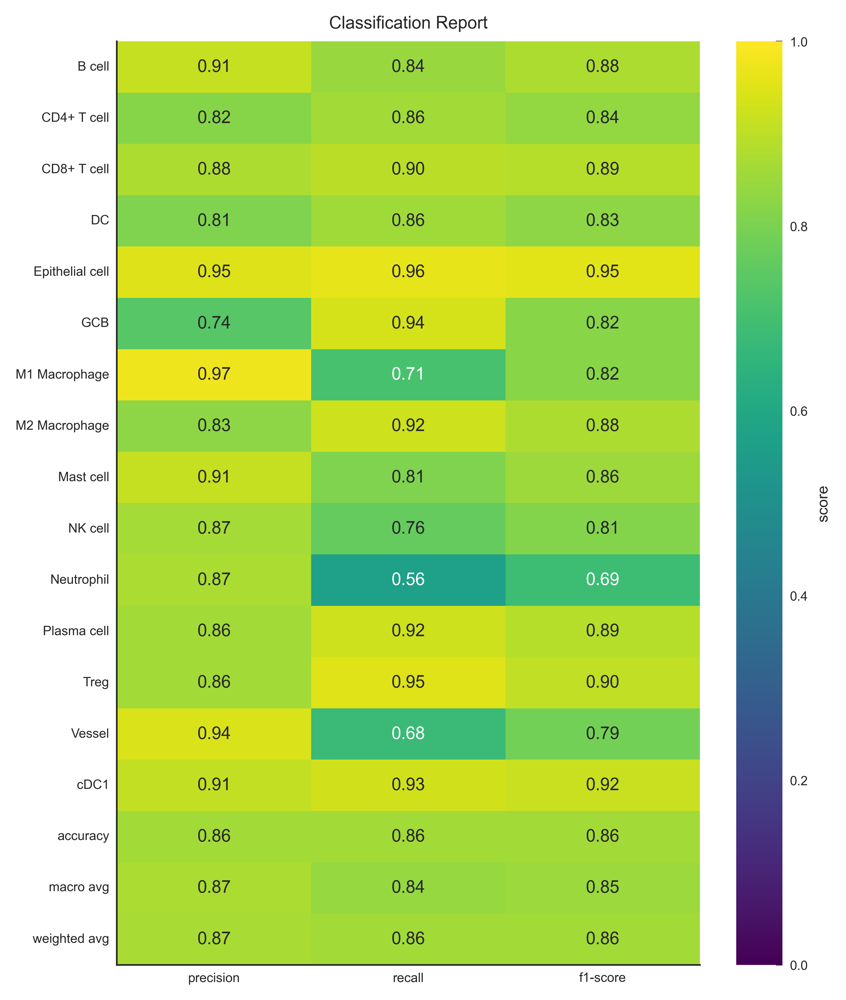

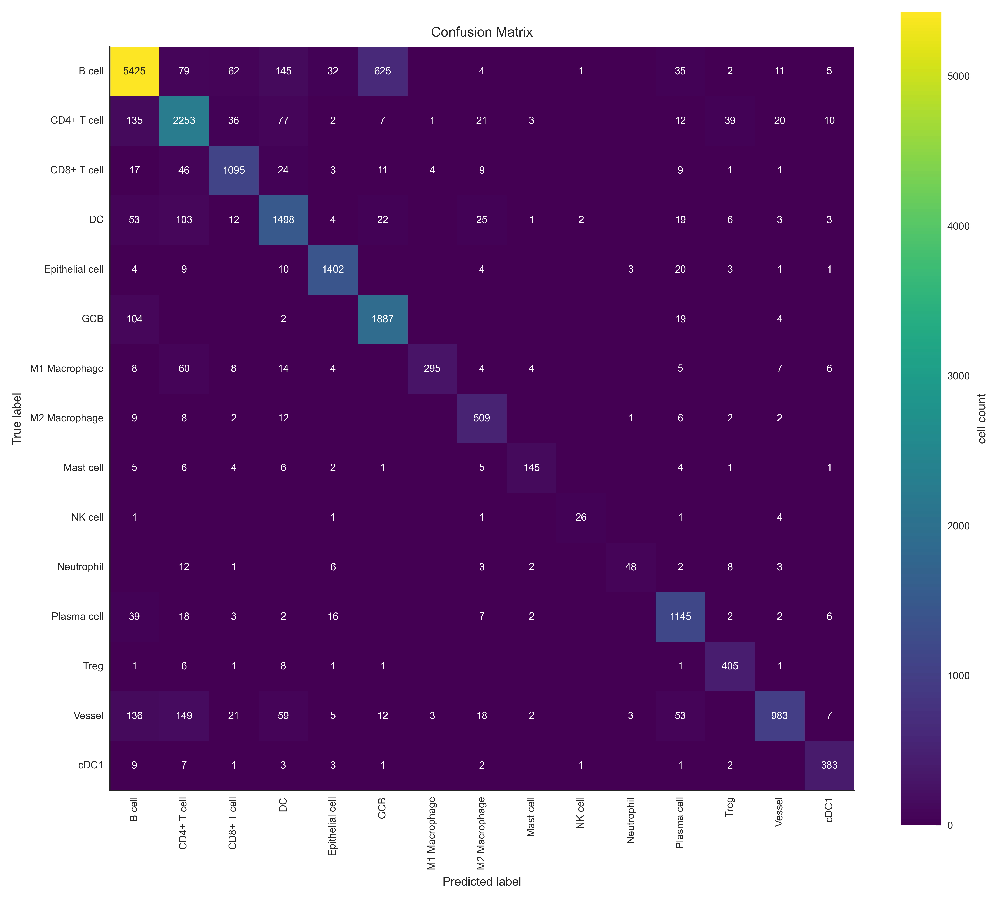

In [20]:
# Compare STELLAR predictions to the known cell_type labels carried over from adata_train
y_true = adata_new.obs['cell_type'].values
y_pred = adata_new.obs['stellar_pred'].values
nan_mask = ~pd.isna(y_true)
y_true = y_true[nan_mask]
y_pred = y_pred[nan_mask]

sp.pl.classification_report_heatmap(y_true=y_true, y_pred=y_pred)
sp.pl.confusion_matrix_heatmap(y_true=y_true, y_pred=y_pred)